# Phân tích benchmark các thuật toán tìm kiếm Bloxorz

Notebook phân tích **lần benchmark đang được lưu trong results.csv**. Kết quả được đọc trực tiếp từ CSV, metadata, test set và báo cáo kiểm chứng heuristic.

**Phạm vi:** BFS, DFS, UCS và A* trên 120 case cố định: 100 bản đồ độc lập BXN và 20 level GUI. Mỗi case được chạy với cả bốn thuật toán.

> **Nguyên tắc:** phân biệt thời gian tìm kiếm với chi phí tiền xử lý H2 của A*; phân biệt độ dài đường đi (số hành động) với tổng chi phí Engine.step_cost; không suy rộng kết quả một lần chạy thành bảo đảm hiệu năng phổ quát.

## 1. Nạp dữ liệu và xác định đúng lần chạy

Notebook có thể chạy từ thư mục gốc repo hoặc từ experiments/. Metadata là nguồn chính để xác định phiên bản dataset, số lần lặp, timeout và môi trường chạy.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd()
ROOT = HERE if (HERE / "experiments" / "results.csv").exists() else HERE.parent
EXP = ROOT / "experiments"
RESULTS_PATH, METADATA_PATH = EXP / "results.csv", EXP / "results_metadata.json"
DATASET_PATH, HEURISTIC_PATH = EXP / "test_set.json", EXP / "heuristic_check.csv"
for path in (RESULTS_PATH, METADATA_PATH, DATASET_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy tệp: {path}")

df = pd.read_csv(RESULTS_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
dataset = json.loads(DATASET_PATH.read_text(encoding="utf-8"))
cases = pd.DataFrame(dataset["cases"])
heuristic_df = pd.read_csv(HEURISTIC_PATH) if HEURISTIC_PATH.exists() else None
algorithm_order = [a for a in ["BFS", "DFS", "UCS", "A*"] if a in df["algorithm"].unique()]
group_order = ["basic", "fragile", "switches_bridges", "combined", "advanced_switches"]
difficulty_order = ["easy", "medium", "hard"]
print(f"CSV: {RESULTS_PATH}")
print(f"Run ID: {metadata.get('run_id')} | UTC: {metadata.get('timestamp_utc')}")
print(f"Dataset version: {metadata.get('dataset_version')} | cases: {len(cases)} | rows: {len(df)}")
print(f"Repeat: {metadata.get('repeat')} | timeout/case: {metadata.get('timeout_seconds_per_solver_case')} s")
print(f"Python: {metadata.get('python_version')} | platform: {metadata.get('platform')}")

CSV: d:\Project_CSAI\Bloxorz_Solver\experiments\results.csv
Run ID: 20261026T065916Z | UTC: 2026-10-26T06:59:33.299000+00:00
Dataset version: 3 | cases: 120 | rows: 480
Repeat: 1 | timeout/case: 15.0 s
Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)] | platform: Windows-10-10.0.26300-SP0


## 2. Kiểm tra tính toàn vẹn của dữ liệu

Trước khi tính trung bình hay vẽ biểu đồ, cần kiểm tra ma trận case–thuật toán, trạng thái chạy, giá trị thiếu và sự nhất quán giữa CSV với dataset/metadata. Trường error để trống ở lượt chạy thành công là bình thường, không được xem là thiếu metric.

In [2]:
expected_algorithms = list(metadata.get("algorithms", []))
dataset_ids, csv_ids = set(cases["case_id"]), set(df["case_id"])
expected_rows = len(cases) * len(expected_algorithms) * int(metadata.get("repeat", 1))
pair_duplicates = int(df.duplicated(["case_id", "algorithm"]).sum())
expected_pairs = {(cid, alg) for cid in dataset_ids for alg in expected_algorithms}
actual_pairs = set(zip(df["case_id"], df["algorithm"]))
audit = pd.DataFrame([
    ("Số dòng CSV", len(df)),
    ("Số dòng kỳ vọng", expected_rows),
    ("Số case dataset / CSV", f"{len(cases)} / {df['case_id'].nunique()}"),
    ("Số thuật toán / run_id", f"{df['algorithm'].nunique()} / {df['run_id'].nunique()}"),
    ("Cặp case–thuật toán trùng", pair_duplicates),
    ("Cặp bị thiếu / ngoài kỳ vọng", f"{len(expected_pairs-actual_pairs)} / {len(actual_pairs-expected_pairs)}"),
    ("Solved / timeout / error", f"{df.status.eq('solved').sum()} / {df.status.eq('timeout').sum()} / {df.status.eq('error').sum()}"),
    ("Case chỉ trong CSV / dataset", f"{len(csv_ids-dataset_ids)} / {len(dataset_ids-csv_ids)}"),
], columns=["Kiểm tra", "Giá trị"])
display(audit)
display(df["status"].value_counts(dropna=False).rename_axis("status").to_frame("số lượt"))
assert len(df) == expected_rows, "Số dòng không khớp kỳ vọng."
assert not pair_duplicates and expected_pairs == actual_pairs, "Ma trận case–thuật toán không đầy đủ hoặc bị trùng."
assert csv_ids == dataset_ids, "CSV và dataset không cùng tập case."
assert df["run_id"].nunique() == 1, "CSV đang chứa nhiều run_id; cần phân tích riêng từng lần chạy."
assert set(df["algorithm"]) == set(expected_algorithms), "Thuật toán không khớp metadata."
metric_cols = ["search_time_seconds", "peak_memory_mb", "expanded_nodes", "solution_length", "total_cost", "preprocessing_time_seconds"]
display(df.groupby("algorithm")[metric_cols].agg(lambda s: s.isna().sum()).rename(columns=lambda c: f"NA: {c}"))
if not df.status.eq("solved").all():
    warnings.warn("Có lượt không solved; bảng chất lượng lời giải sẽ chỉ dùng solved.")
else:
    print("Xác minh: mọi lượt đều solved; không timeout/error.")

,Kiểm tra,Giá trị
0,Số dòng CSV,480
1,Số dòng kỳ vọng,480
2,Số case dataset / CSV,120 / 120
3,Số thuật toán / run_id,4 / 1
4,Cặp case–thuật toán trùng,0
5,Cặp bị thiếu / ngoài kỳ vọng,0 / 0
6,Solved / timeout / error,480 / 0 / 0
7,Case chỉ trong CSV / dataset,0 / 0


,số lượt
status,
solved,480


,NA: search_time_seconds,NA: peak_memory_mb,NA: expanded_nodes,NA: solution_length,NA: total_cost,NA: preprocessing_time_seconds
algorithm,,,,,,
A*,0,0,0,0,0,0
BFS,0,0,0,0,0,0
DFS,0,0,0,0,0,0
UCS,0,0,0,0,0,0


Xác minh: mọi lượt đều solved; không timeout/error.


## 3. Cấu trúc và phạm vi của bộ test

Dataset phiên bản 3 kết hợp bản đồ thiết kế độc lập với các level GUI đã nhúng. Các nhóm có kích thước khác nhau, vì vậy khi so sánh theo nhóm cần đọc kèm số lượng case n.

In [3]:
group_counts = cases["group"].value_counts().reindex(group_order).dropna().astype(int)
difficulty_counts = cases["difficulty"].value_counts().reindex(difficulty_order).dropna().astype(int)
source_type = cases["case_id"].astype(str).str.startswith("GUI-").map({True: "Level GUI", False: "Bản đồ độc lập"})
composition = cases.assign(source_type=source_type).groupby(["group", "source_type"]).size().unstack(fill_value=0)
composition = composition.reindex(group_order).fillna(0).astype(int)
print(f"Dataset version: {dataset.get('dataset_version')} | Tổng case: {len(cases)}")
display(composition)
display(difficulty_counts.rename("số case").to_frame())
group_descriptions = {
    "basic": "Địa hình cơ bản, không có mechanics đặc biệt.",
    "fragile": "Có ô dễ vỡ.",
    "switches_bridges": "Có soft switch điều khiển cầu.",
    "combined": "Kết hợp ô dễ vỡ và cầu/công tắc.",
    "advanced_switches": "Có heavy switch hoặc split switch; level GUI nâng cao."
}
display(pd.DataFrame({"Nhóm": group_counts.index, "Số case": group_counts.values,
                      "Mô tả": [group_descriptions.get(g, "") for g in group_counts.index]}))

Dataset version: 3 | Tổng case: 120


source_type,Bản đồ độc lập,Level GUI
group,,
basic,25,3
fragile,25,3
switches_bridges,25,3
combined,25,0
advanced_switches,0,11


,số case
difficulty,
easy,46
medium,54
hard,20


,Nhóm,Số case,Mô tả
0,basic,28,"Địa hình cơ bản, không có mechanics đặc biệt."
1,fragile,28,Có ô dễ vỡ.
2,switches_bridges,28,Có soft switch điều khiển cầu.
3,combined,25,Kết hợp ô dễ vỡ và cầu/công tắc.
4,advanced_switches,11,Có heavy switch hoặc split switch; level GUI n...


## 4. Định nghĩa metric và giới hạn đo lường

- **Search time:** search_time_seconds do solver báo cáo; không phải wall-clock của toàn bộ pipeline.
- **Preprocessing time:** thời gian dựng H2 của A*. Runner xoá cache H2 trước mỗi lượt nên heuristic được dựng lại.
- **Observed solver time:** search + preprocessing. Đây là tổng hai phần solver được ghi nhận, không gồm thời gian ngoài solver.
- **Expanded nodes:** số trạng thái được mở rộng; trạng thái đích không tính.
- **Peak memory:** bộ nhớ cấp phát Python do tracemalloc theo dõi, không phải RSS/tổng RAM.
- **Solution length:** số hành động trong đường đi.
- **Total cost:** tổng Engine.step_cost. Đường ít hành động nhất không nhất thiết có tổng chi phí thấp nhất.
- **Status:** trạng thái kết thúc; tỷ lệ thành công chỉ áp dụng cho dataset và timeout này.

In [4]:
df["is_solved"] = df["status"].eq("solved")
df["search_time_ms"] = df["search_time_seconds"] * 1000
df["preprocessing_time_ms"] = df["preprocessing_time_seconds"].fillna(0) * 1000
df["observed_solver_time_ms"] = df["search_time_ms"] + df["preprocessing_time_ms"]
solved_df = df[df["is_solved"]].copy()
summary_rows = []
for alg in algorithm_order:
    part, solved = df[df.algorithm.eq(alg)], solved_df[solved_df.algorithm.eq(alg)]
    summary_rows.append({
        "Thuật toán": alg, "Lượt chạy": len(part),
        "Thành công (%)": 100 * part.is_solved.mean(),
        "Search TB (ms)": part.search_time_ms.mean(),
        "Search median (ms)": part.search_time_ms.median(),
        "Search P95 (ms)": part.search_time_ms.quantile(.95),
        "Preprocess TB (ms)": part.preprocessing_time_ms.mean(),
        "Solver time TB (ms)": part.observed_solver_time_ms.mean(),
        "Expanded TB": solved.expanded_nodes.mean(),
        "Peak memory TB (MB)": solved.peak_memory_mb.mean(),
        "Độ dài TB": solved.solution_length.mean(),
        "Chi phí TB": solved.total_cost.mean(),
    })
summary = pd.DataFrame(summary_rows).set_index("Thuật toán")
display(summary.round(4).style.format(precision=3))

,Lượt chạy,Thành công (%),Search TB (ms),Search median (ms),Search P95 (ms),Preprocess TB (ms),Solver time TB (ms),Expanded TB,Peak memory TB (MB),Độ dài TB,Chi phí TB
Thuật toán,,,,,,,,,,,
BFS,120,100.000,42.615,19.735,52.671,0.000,42.615,418.950,0.072,27.208,32.340
DFS,120,100.000,21.575,17.066,40.389,0.000,21.575,196.333,0.045,94.025,113.688
UCS,120,100.000,43.331,21.501,58.857,0.000,43.331,391.958,0.094,27.208,32.295
A*,120,100.000,12.253,3.405,36.089,18.277,30.530,87.233,0.160,27.208,32.295


## 5. So sánh hiệu năng tổng thể

### 5.1. Thời gian tìm kiếm và chi phí tiền xử lý

A* có thể giảm công việc tìm kiếm nhờ heuristic, nhưng thời gian dựng H2 cũng là chi phí thực tế. Vì runner xoá cache H2 trước mỗi lượt, kết quả phản ánh chế độ **cold preprocessing**, không phải ứng dụng tái sử dụng cache giữa nhiều truy vấn.

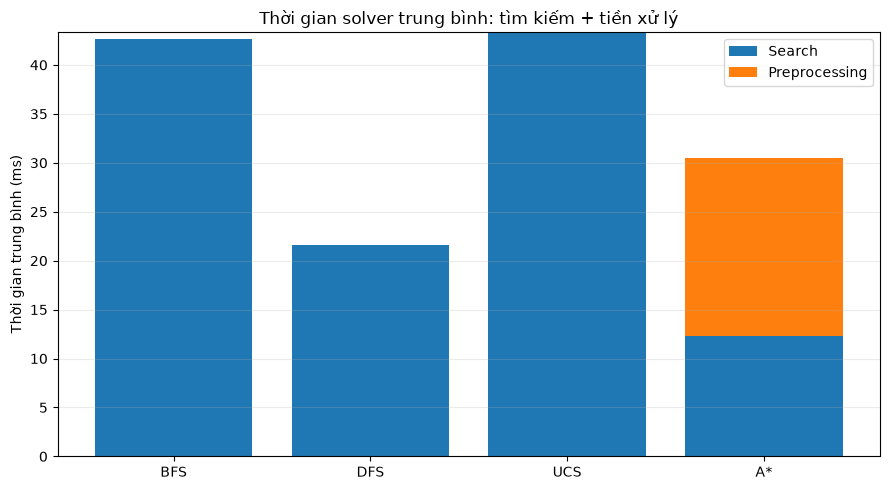

,Search TB (ms),Preprocess TB (ms),Solver time TB (ms)
Thuật toán,,,
BFS,42.615,0.000,42.615
DFS,21.574,0.000,21.574
UCS,43.331,0.000,43.331
A*,12.253,18.277,30.530


In [5]:
x = np.arange(len(algorithm_order))
search_means = [summary.loc[a, "Search TB (ms)"] for a in algorithm_order]
prep_means = [summary.loc[a, "Preprocess TB (ms)"] for a in algorithm_order]
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, search_means, label="Search")
ax.bar(x, prep_means, bottom=search_means, label="Preprocessing")
ax.set_xticks(x, algorithm_order)
ax.set_ylabel("Thời gian trung bình (ms)")
ax.set_title("Thời gian solver trung bình: tìm kiếm + tiền xử lý")
ax.legend(); ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()
display(summary[["Search TB (ms)", "Preprocess TB (ms)", "Solver time TB (ms)"]].round(3))

### 5.2. Lượng tìm kiếm, bộ nhớ và chất lượng lời giải

Số trạng thái mở rộng phản ánh lượng công việc theo bộ đếm solver, không thay thế cho thời gian. Bộ nhớ là phần cấp phát Python mà tracemalloc quan sát.

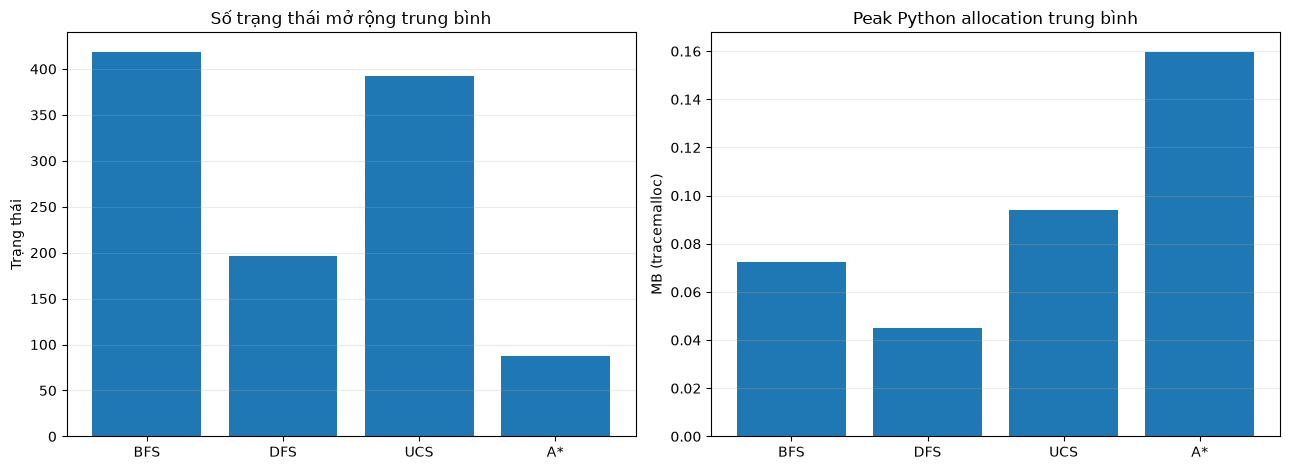

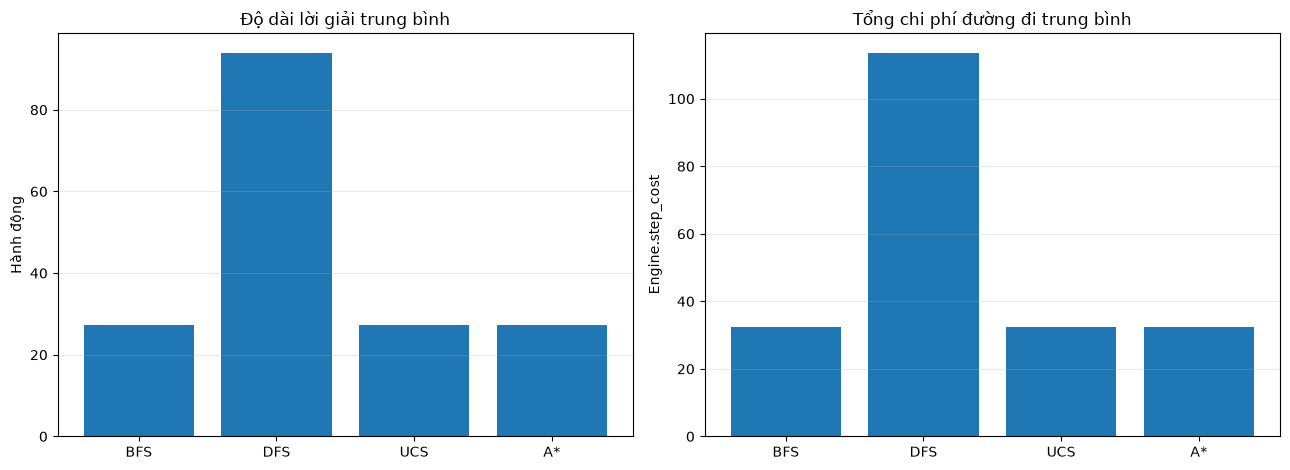

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(algorithm_order, [summary.loc[a, "Expanded TB"] for a in algorithm_order])
axes[0].set_title("Số trạng thái mở rộng trung bình"); axes[0].set_ylabel("Trạng thái"); axes[0].grid(axis="y", alpha=.25)
axes[1].bar(algorithm_order, [summary.loc[a, "Peak memory TB (MB)"] for a in algorithm_order])
axes[1].set_title("Peak Python allocation trung bình"); axes[1].set_ylabel("MB (tracemalloc)"); axes[1].grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(algorithm_order, [summary.loc[a, "Độ dài TB"] for a in algorithm_order])
axes[0].set_title("Độ dài lời giải trung bình"); axes[0].set_ylabel("Hành động")
axes[1].bar(algorithm_order, [summary.loc[a, "Chi phí TB"] for a in algorithm_order])
axes[1].set_title("Tổng chi phí đường đi trung bình"); axes[1].set_ylabel("Engine.step_cost")
for ax in axes: ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()

### 5.3. Phân phối thời gian

Mỗi thuật toán chỉ có một phép đo cho mỗi case ở lần chạy này. Boxplot mô tả độ phân tán giữa các case, **không** phải độ biến thiên do lặp cùng case nhiều lần.

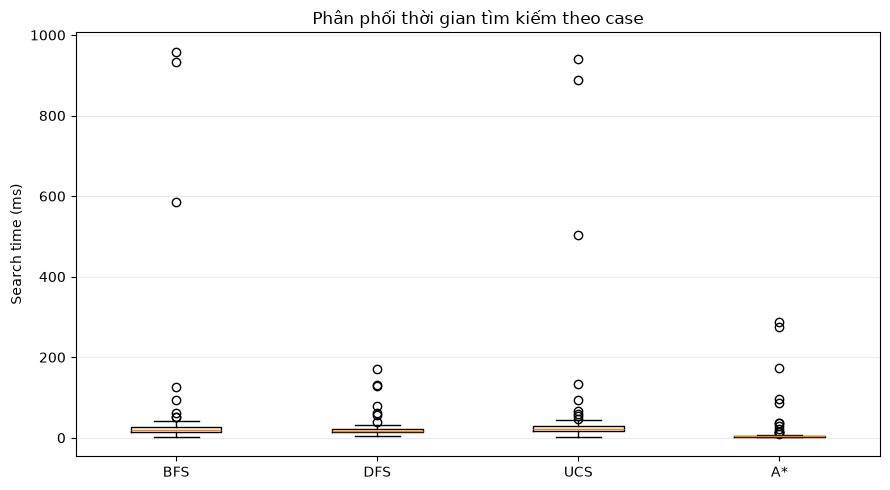

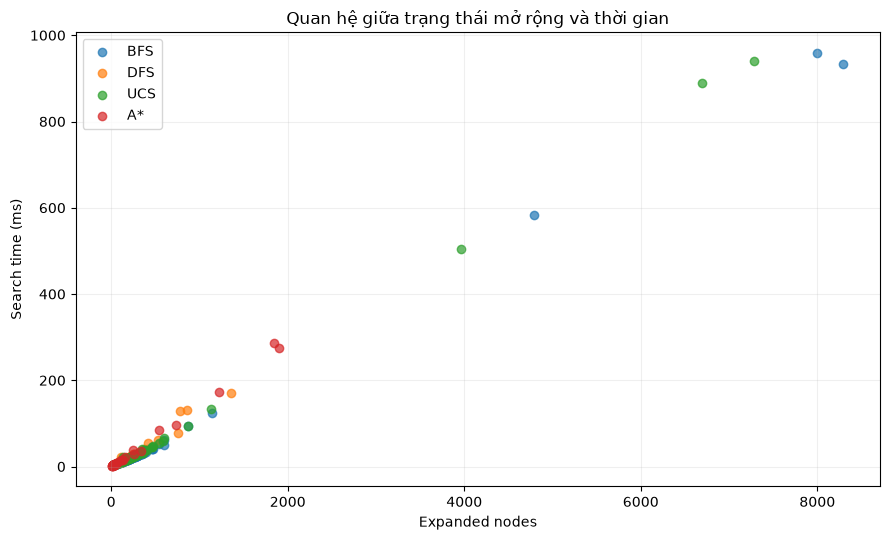

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
time_data = [solved_df.loc[solved_df.algorithm.eq(a), "search_time_ms"].dropna().to_numpy() for a in algorithm_order]
ax.boxplot(time_data, tick_labels=algorithm_order, showfliers=True)
ax.set_ylabel("Search time (ms)"); ax.set_title("Phân phối thời gian tìm kiếm theo case")
ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(9, 5.5))
for alg in algorithm_order:
    part = solved_df[solved_df.algorithm.eq(alg)]
    ax.scatter(part.expanded_nodes, part.search_time_ms, label=alg, alpha=.7)
ax.set_xlabel("Expanded nodes"); ax.set_ylabel("Search time (ms)")
ax.set_title("Quan hệ giữa trạng thái mở rộng và thời gian"); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 6. Phân tích theo nhóm mechanics

Các nhóm cơ bản có 25–28 case; advanced_switches chỉ có 11 level GUI.

,group,algorithm,n,search_ms_mean,solver_ms_mean,expanded_mean,memory_mb_mean,length_mean,cost_mean
4,basic,A*,28,3.416,17.377,25.214,0.125,23.143,27.411
5,basic,BFS,28,16.701,16.701,189.786,0.028,23.143,27.464
6,basic,DFS,28,15.799,15.799,153.714,0.034,69.000,81.071
7,basic,UCS,28,18.037,18.037,188.536,0.037,23.143,27.411
12,fragile,A*,28,3.801,18.288,29.250,0.126,23.750,28.071
13,fragile,BFS,28,16.234,16.234,184.107,0.027,23.750,28.089
14,fragile,DFS,28,14.989,14.989,144.750,0.032,72.071,84.554
15,fragile,UCS,28,17.629,17.629,183.929,0.036,23.750,28.071
16,switches_bridges,A*,28,4.040,18.243,30.750,0.127,24.929,29.589
17,switches_bridges,BFS,28,25.254,25.254,286.464,0.043,24.929,29.589


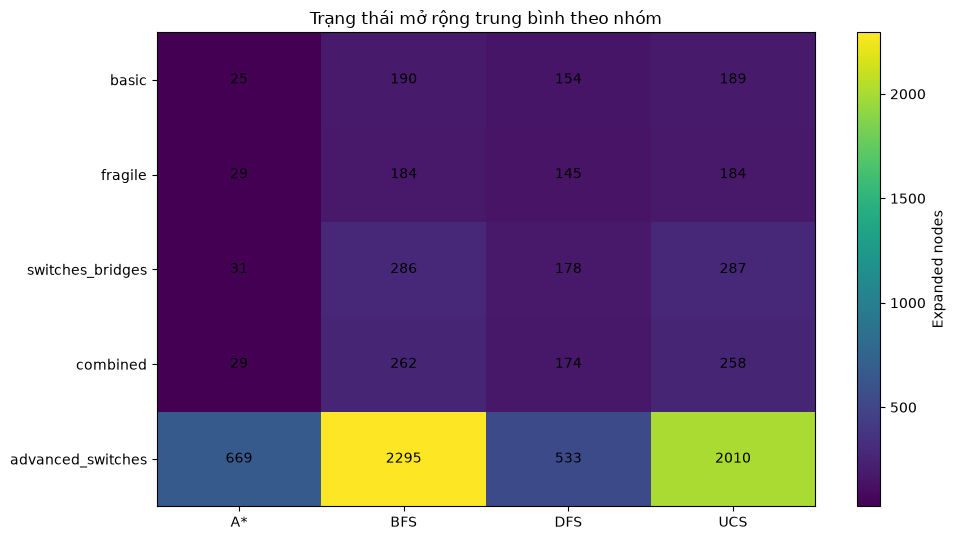

algorithm,A*,BFS,DFS,UCS
group,,,,
basic,17.38,16.70,15.80,18.04
fragile,18.29,16.23,14.99,17.63
switches_bridges,18.24,25.25,18.59,27.87
combined,19.54,23.33,18.06,24.91
advanced_switches,151.44,263.75,68.62,254.35


In [8]:
group_metrics = (solved_df.groupby(["group", "algorithm"], observed=True)
    .agg(n=("case_id", "nunique"), search_ms_mean=("search_time_ms", "mean"),
         solver_ms_mean=("observed_solver_time_ms", "mean"), expanded_mean=("expanded_nodes", "mean"),
         memory_mb_mean=("peak_memory_mb", "mean"), length_mean=("solution_length", "mean"),
         cost_mean=("total_cost", "mean")).reset_index())
group_metrics["group"] = pd.Categorical(group_metrics["group"], categories=group_order, ordered=True)
group_metrics = group_metrics.sort_values(["group", "algorithm"])
display(group_metrics.round(3))
pivot_expanded = group_metrics.pivot(index="group", columns="algorithm", values="expanded_mean").reindex(group_order)
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(pivot_expanded.to_numpy(), aspect="auto")
ax.set_xticks(np.arange(len(pivot_expanded.columns)), pivot_expanded.columns)
ax.set_yticks(np.arange(len(pivot_expanded.index)), pivot_expanded.index)
ax.set_title("Trạng thái mở rộng trung bình theo nhóm")
for i in range(pivot_expanded.shape[0]):
    for j in range(pivot_expanded.shape[1]):
        ax.text(j, i, f"{pivot_expanded.iloc[i, j]:.0f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Expanded nodes")
plt.tight_layout(); plt.show()
display(group_metrics.pivot(index="group", columns="algorithm", values="solver_ms_mean").reindex(group_order).round(2))

## 7. Phân tích theo nhãn độ khó

Nhãn easy/medium/hard được lấy từ test_set.json và dựa gần đúng trên độ dài lời giải BFS tham chiếu. Đây là chỉ số đại diện, không phải thước đo toàn diện: branching factor, số state reachable và tương tác mechanics cũng ảnh hưởng đến độ khó.

,difficulty,algorithm,n,search_ms_mean,solver_ms_mean,expanded_mean,memory_mb_mean,length_mean,cost_mean
0,easy,A*,46,3.070,16.783,22.457,0.120,18.674,22.154
1,easy,BFS,46,18.041,18.041,205.196,0.031,18.674,22.174
2,easy,DFS,46,16.370,16.370,155.217,0.035,74.565,87.424
3,easy,UCS,46,20.161,20.161,205.391,0.042,18.674,22.154
8,medium,A*,54,4.069,19.963,29.926,0.140,25.481,30.196
9,medium,BFS,54,24.582,24.582,272.148,0.040,25.481,30.270
10,medium,DFS,54,18.557,18.557,177.685,0.038,83.852,99.741
11,medium,UCS,54,26.430,26.430,270.593,0.054,25.481,30.196
4,hard,A*,20,55.473,90.681,390.950,0.305,51.500,61.285
5,hard,BFS,20,147.826,147.826,1306.950,0.255,51.500,61.310


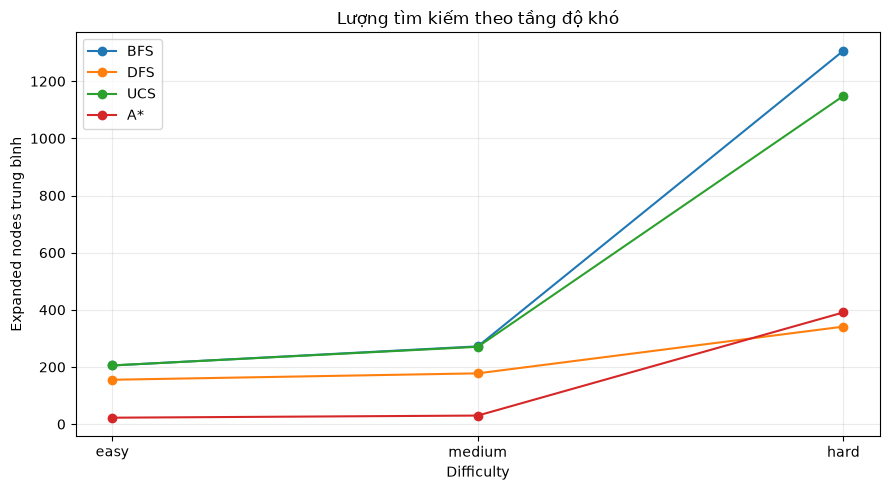

In [9]:
difficulty_metrics = (solved_df.groupby(["difficulty", "algorithm"], observed=True)
    .agg(n=("case_id", "nunique"), search_ms_mean=("search_time_ms", "mean"),
         solver_ms_mean=("observed_solver_time_ms", "mean"), expanded_mean=("expanded_nodes", "mean"),
         memory_mb_mean=("peak_memory_mb", "mean"), length_mean=("solution_length", "mean"),
         cost_mean=("total_cost", "mean")).reset_index())
difficulty_metrics["difficulty"] = pd.Categorical(difficulty_metrics["difficulty"], categories=difficulty_order, ordered=True)
difficulty_metrics = difficulty_metrics.sort_values(["difficulty", "algorithm"])
display(difficulty_metrics.round(3))
pivot_difficulty = difficulty_metrics.pivot(index="difficulty", columns="algorithm", values="expanded_mean").reindex(difficulty_order)
fig, ax = plt.subplots(figsize=(9, 5))
for alg in algorithm_order:
    ax.plot(pivot_difficulty.index.astype(str), pivot_difficulty[alg], marker="o", label=alg)
ax.set_xlabel("Difficulty"); ax.set_ylabel("Expanded nodes trung bình")
ax.set_title("Lượng tìm kiếm theo tầng độ khó"); ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 8. Kiểm chứng heuristic H1/H2

In [10]:
if heuristic_df is None:
    print("Không tìm thấy heuristic_check.csv; bỏ qua phần này.")
else:
    hcols = [c for c in heuristic_df.columns if c.endswith("_violations") or c.endswith("_nonzero")]
    display(pd.DataFrame({"Chỉ số": hcols,
        "Tổng vi phạm": [int(heuristic_df[c].sum()) for c in hcols],
        "Số case có vi phạm": [int((heuristic_df[c] > 0).sum()) for c in hcols]}))
    display(heuristic_df[["states", "edges", "dead_end_states"]].sum().rename("Tổng trên các case").to_frame())
    for heuristic in ["H2", "H1"]:
        for suffix, label in [("admissible_violations", "admissibility"),
                              ("consistent_violations", "consistency"), ("goal_nonzero", "h(goal)=0")]:
            col = f"{heuristic}_{suffix}"
            if col in heuristic_df:
                bad = heuristic_df.loc[heuristic_df[col] > 0, ["case_id", col]]
                if len(bad):
                    print(f"{heuristic}: case có vi phạm {label}"); display(bad)
                else:
                    print(f"{heuristic}: không ghi nhận vi phạm {label} trong dữ liệu kiểm tra.")

,Chỉ số,Tổng vi phạm,Số case có vi phạm
0,H2_admissible_violations,0,0
1,H2_consistent_violations,0,0
2,H2_goal_nonzero,0,0
3,H1_admissible_violations,0,0
4,H1_consistent_violations,21,5
5,H1_goal_nonzero,0,0


,Tổng trên các case
states,115043
edges,379858
dead_end_states,18442


H2: không ghi nhận vi phạm admissibility trong dữ liệu kiểm tra.
H2: không ghi nhận vi phạm consistency trong dữ liệu kiểm tra.
H2: không ghi nhận vi phạm h(goal)=0 trong dữ liệu kiểm tra.
H1: không ghi nhận vi phạm admissibility trong dữ liệu kiểm tra.
H1: case có vi phạm consistency


,case_id,H1_consistent_violations
107,GUI-008,1
108,GUI-009,1
109,GUI-010,1
114,GUI-015,2
116,GUI-017,16


H1: không ghi nhận vi phạm h(goal)=0 trong dữ liệu kiểm tra.


## 9. Các case tốn tài nguyên nhất

Bảng này liệt kê các case có search time cao nhất của từng thuật toán.

In [11]:
slow_rows = []
for alg in algorithm_order:
    for _, row in solved_df[solved_df.algorithm.eq(alg)].nlargest(5, "search_time_ms").iterrows():
        slow_rows.append({"Thuật toán": alg, "Case": row.case_id, "Nhóm": row.group,
            "Độ khó": row.difficulty, "Search (ms)": row.search_time_ms,
            "Preprocess (ms)": row.preprocessing_time_ms, "Expanded": row.expanded_nodes,
            "Peak MB": row.peak_memory_mb, "Length": row.solution_length, "Cost": row.total_cost})
display(pd.DataFrame(slow_rows).round(3))

,Thuật toán,Case,Nhóm,Độ khó,Search (ms),Preprocess (ms),Expanded,Peak MB,Length,Cost
0,BFS,GUI-015,advanced_switches,hard,958.896,0.000,8002,1.704,61,79.4
1,BFS,GUI-017,advanced_switches,hard,932.941,0.000,8296,1.767,58,70.2
2,BFS,GUI-010,advanced_switches,hard,584.338,0.000,4786,0.937,37,45.6
3,BFS,GUI-009,advanced_switches,medium,125.268,0.000,1146,0.177,22,28.1
4,BFS,GUI-020,advanced_switches,hard,94.300,0.000,872,0.121,91,108.0
5,DFS,GUI-017,advanced_switches,hard,170.901,0.000,1359,0.400,318,414.5
6,DFS,GUI-010,advanced_switches,hard,130.457,0.000,859,0.305,788,1102.9
7,DFS,GUI-015,advanced_switches,hard,128.059,0.000,783,0.220,658,885.2
8,DFS,GUI-020,advanced_switches,hard,78.874,0.000,752,0.156,210,247.0
9,DFS,GUI-019,advanced_switches,hard,61.768,0.000,528,0.109,204,243.0


## 10. Kết luận từ lần chạy hiện tại

In [12]:
best_search = summary["Search TB (ms)"].idxmin()
fewest_expanded = summary["Expanded TB"].idxmin()
lowest_memory = summary["Peak memory TB (MB)"].idxmin()
shortest_length = summary["Độ dài TB"].idxmin()
lowest_cost = summary["Chi phí TB"].idxmin()
print(f"Search trung bình thấp nhất: {best_search} ({summary.loc[best_search, 'Search TB (ms)']:.2f} ms).")
print(f"Expanded trung bình thấp nhất: {fewest_expanded} ({summary.loc[fewest_expanded, 'Expanded TB']:.2f}).")
print(f"Peak tracemalloc trung bình thấp nhất: {lowest_memory} ({summary.loc[lowest_memory, 'Peak memory TB (MB)']:.4f} MB).")
print(f"Độ dài lời giải trung bình thấp nhất: {shortest_length} ({summary.loc[shortest_length, 'Độ dài TB']:.2f} hành động).")
print(f"Chi phí trung bình thấp nhất: {lowest_cost} ({summary.loc[lowest_cost, 'Chi phí TB']:.4f}).")
if "A*" in summary.index:
    print(f"A*: search {summary.loc['A*', 'Search TB (ms)']:.2f} ms; preprocessing {summary.loc['A*', 'Preprocess TB (ms)']:.2f} ms; tổng hai phần {summary.loc['A*', 'Solver time TB (ms)']:.2f} ms.")
if {"DFS", "BFS"}.issubset(summary.index) and summary.loc["BFS", "Độ dài TB"]:
    print(f"Đường đi DFS trung bình dài gấp {summary.loc['DFS', 'Độ dài TB']/summary.loc['BFS', 'Độ dài TB']:.2f} lần BFS.")
display(Markdown(f"**Run {metadata.get('run_id')}:** {len(df)} lượt trên {df.case_id.nunique()} case; tỷ lệ solved {100*df.is_solved.mean():.1f}%; repeat={metadata.get('repeat')}; timeout={metadata.get('timeout_seconds_per_solver_case')} giây/lượt."))

Search trung bình thấp nhất: A* (12.25 ms).
Expanded trung bình thấp nhất: A* (87.23).
Peak tracemalloc trung bình thấp nhất: DFS (0.0451 MB).
Độ dài lời giải trung bình thấp nhất: BFS (27.21 hành động).
Chi phí trung bình thấp nhất: UCS (32.2950).
A*: search 12.25 ms; preprocessing 18.28 ms; tổng hai phần 30.53 ms.
Đường đi DFS trung bình dài gấp 3.46 lần BFS.


**Run 20261026T065916Z:** 480 lượt trên 120 case; tỷ lệ solved 100.0%; repeat=1; timeout=15.0 giây/lượt.